# Parte 1 — O primeiro modelo em produção

**Banco Aurora · Prevenção a Fraudes** · entrega: **quarta-feira, 11/11, 23h59**

Leia antes o `demanda_parte1.md`: é o pedido do negócio. Este notebook é o roteiro técnico para atendê-lo.

**Como este notebook funciona**
- Cada seção diz **o que** fazer e **por quê**. O código é seu.
- Duas células vêm prontas (seção 0 e seção 10): elas são encanamento, não conteúdo.
- Tudo que será reutilizado nas partes 2 e 3 vai para arquivos `.py` (`features.py`, `monitoramento.py`), não fica só no notebook.
- Rode a partir da raiz do projeto, com o **MLflow** e o **sistema** no ar (veja o `README.md`).

**O que será avaliado nesta parte**
1. O contrato de features é respeitado no treino e na inferência.
2. O modelo está registrado e rastreável no MLflow, como `@champion`.
3. O threshold é justificado pelo custo de negócio.
4. O monitoramento está pronto **antes** do primeiro lote chegar.

O algoritmo é escolha sua. **Não existe ranking de performance**: existe um piso (seção 5) e existe a qualidade da justificativa.

## 0. Ambiente

Rode a célula abaixo. Se algo aparecer como `FALHOU`, resolva antes de seguir: o resto do notebook depende das quatro conexões.

In [69]:
# CÉLULA PRONTA — só rode. Tudo precisa aparecer como "ok".
import json
import urllib.request

import mlflow
import psycopg2

import config

for nome, uri in [("Postgres / antifraude", config.URI_BANCO_APP), ("Postgres / mlflow", config.URI_BANCO_MLFLOW)]:
    try:
        psycopg2.connect(uri).close()
        print(f"{nome:24} ok")
    except Exception as e:
        print(f"{nome:24} FALHOU -> {e}")

for nome, url in [("MLflow", f"{config.MLFLOW_TRACKING_URI}/health"), ("Sistema", f"{config.SISTEMA_URL}/saude")]:
    try:
        resp = urllib.request.urlopen(url, timeout=5).read().decode()
        print(f"{nome:24} ok -> {resp[:160]}")
    except Exception as e:
        print(f"{nome:24} FALHOU -> {e}")

mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
print("\ntracking uri:", mlflow.get_tracking_uri())

Postgres / antifraude    ok
Postgres / mlflow        ok
MLflow                   ok -> OK
Sistema                  ok -> {"sistema":"ok","contrato":"1.0","modelo":{"ok":true,"versao":"3","threshold":0.29,"run_id":"7260ffdde12740b38a547f1a41c50a98","descricao":"Algoritmo: random_fo

tracking uri: http://127.0.0.1:5000


## 1. O contrato

O contrato (`contrato/contrato_features.yaml`) é o acordo com o time de Plataforma: as 13 features que o sistema de produção entrega, com tipo, regra de cálculo e valores permitidos. **O sistema rejeita qualquer lote que não o respeite**, e o seu modelo vai receber exatamente isso — nada mais.

**Faça**
1. Leia o YAML com `yaml.safe_load` e monte, a partir dele (não digitando à mão), a lista das features na ordem do contrato, separando categóricas e numéricas.
2. Carregue `dados/transacoes_semanas_01_12.csv` e `dados/rotulos_semanas_01_12.csv` e junte os dois pela `id_transacao`. Garanta que a junção é 1 para 1 e que nenhuma linha se perdeu.
3. Escreva uma validação do histórico contra o contrato: colunas presentes, tipos, valores fora da lista nas categóricas, valores fora de `min`/`max`, nulos. O histórico passa?

> Por que validar um dado que "veio do próprio banco"? Porque o modelo vai aprender o que estiver aqui. Se o treino tiver algo que a produção não terá (ou o contrário), o erro só aparece depois, em produção.

In [50]:
from pathlib import Path

import pandas as pd
import yaml

contrato = yaml.safe_load(Path("contrato/contrato_features.yaml").read_text(encoding="utf-8"))
features_contrato = [f["nome"] for f in contrato["features"]]
features_numericas = [f["nome"] for f in contrato["features"] if f["tipo"] in {"int", "float", "bool"}]
features_categoricas = [f["nome"] for f in contrato["features"] if f["tipo"] == "categoria"]

print(f"Contrato v{contrato['versao']} — {len(features_contrato)} features")
print("Ordem do contrato:", features_contrato)
print("Numéricas:", features_numericas)
print("Categóricas:", features_categoricas)

Contrato v1.0 — 13 features
Ordem do contrato: ['valor_transacao', 'hora_transacao', 'dia_semana', 'canal', 'dispositivo_novo', 'qtd_transacoes_1h', 'valor_medio_30d', 'razao_valor_media', 'distancia_ultima_transacao_km', 'idade_conta_dias', 'destinatario_novo', 'categoria_estabelecimento', 'uf_cliente']
Numéricas: ['valor_transacao', 'hora_transacao', 'dia_semana', 'dispositivo_novo', 'qtd_transacoes_1h', 'valor_medio_30d', 'razao_valor_media', 'distancia_ultima_transacao_km', 'idade_conta_dias', 'destinatario_novo']
Categóricas: ['canal', 'categoria_estabelecimento', 'uf_cliente']


In [51]:
transacoes = pd.read_csv("dados/transacoes_semanas_01_12.csv", dtype={"id_transacao": str, "id_cliente": str})
rotulos = pd.read_csv("dados/rotulos_semanas_01_12.csv", dtype={"id_transacao": str})

assert transacoes["id_transacao"].is_unique, "Transações têm id_transacao duplicado"
assert rotulos["id_transacao"].is_unique, "Rótulos têm id_transacao duplicado"

historico = transacoes.merge(rotulos, on="id_transacao", how="inner", validate="one_to_one", indicator=True)
assert len(historico) == len(transacoes) == len(rotulos), "A junção perdeu ou duplicou linhas"
assert (historico["_merge"] == "both").all()
historico = historico.drop(columns="_merge")

print(f"Transações: {len(transacoes):,} | Rótulos: {len(rotulos):,} | Juntas: {len(historico):,}")
print("Junção 1:1 e sem perda: OK")

Transações: 240,384 | Rótulos: 240,384 | Juntas: 240,384
Junção 1:1 e sem perda: OK


In [52]:
from app.contrato import validar

# O rótulo é alvo do treino, não faz parte do lote de features do contrato.
colunas_entrada = contrato.get("metadados", []) + features_contrato
historico_para_validar = historico[colunas_entrada].copy()
historico_tipado, erros_contrato = validar(historico_para_validar, contrato=contrato, exigir_uma_semana=False)

print("Resultado da validação do histórico:", "PASSA" if not erros_contrato else "NÃO PASSA")
if erros_contrato:
    for erro in erros_contrato:
        print(f"- {erro}")
else:
    print(f"{len(historico_tipado):,} linhas válidas; nulos, tipos, limites e categorias: OK")

Resultado da validação do histórico: PASSA
240,384 linhas válidas; nulos, tipos, limites e categorias: OK


## 2. Divisão temporal

A regra combinada com o negócio: **treino nas semanas 1 a 10, validação nas semanas 11 e 12**.

**Faça**
1. Separe os dois conjuntos pela coluna `semana`.
2. Mostre a taxa de fraude por semana e o tamanho de cada conjunto.
3. Responda em uma célula de texto: por que uma divisão aleatória (`train_test_split`) seria um erro aqui?

In [53]:
semanas_treino = list(range(1, 11))
semanas_validacao = [11, 12]

treino = historico[historico["semana"].isin(semanas_treino)].copy()
validacao = historico[historico["semana"].isin(semanas_validacao)].copy()

assert set(treino["semana"].unique()) == set(semanas_treino)
assert set(validacao["semana"].unique()) == set(semanas_validacao)
assert len(treino) + len(validacao) == len(historico)

print(f"Treino: {len(treino):,} linhas | semanas {semanas_treino[0]}–{semanas_treino[-1]}")
print(f"Validação: {len(validacao):,} linhas | semanas {semanas_validacao}")

Treino: 200,887 linhas | semanas 1–10
Validação: 39,497 linhas | semanas [11, 12]


In [54]:
from IPython.display import display

resumo_semanal = (
    historico.groupby("semana", as_index=False)
    .agg(transacoes=("id_transacao", "size"),
         fraudes=("fraude", "sum"))
)
resumo_semanal["taxa_fraude"] = resumo_semanal["fraudes"] / resumo_semanal["transacoes"]
resumo_semanal["conjunto"] = resumo_semanal["semana"].apply(
    lambda s: "treino" if s in semanas_treino else "validação"
)
resumo_semanal = resumo_semanal[["semana", "conjunto", "transacoes", "fraudes", "taxa_fraude"]]
display(resumo_semanal.style.format({"taxa_fraude": "{:.2%}"}))

resumo_conjuntos = (
    historico.assign(conjunto=historico["semana"].apply(
        lambda s: "treino" if s in semanas_treino else "validação"))
    .groupby("conjunto")
    .agg(transacoes=("id_transacao", "size"), fraudes=("fraude", "sum"))
)
resumo_conjuntos["taxa_fraude"] = resumo_conjuntos["fraudes"] / resumo_conjuntos["transacoes"]
display(resumo_conjuntos.style.format({"taxa_fraude": "{:.2%}"}))

,semana,conjunto,transacoes,fraudes,taxa_fraude
0,1,treino,20160,297,1.47%
1,2,treino,19811,282,1.42%
2,3,treino,20283,249,1.23%
3,4,treino,19995,263,1.32%
4,5,treino,20318,371,1.83%
5,6,treino,20479,298,1.46%
6,7,treino,20307,277,1.36%
7,8,treino,19706,306,1.55%
8,9,treino,20006,234,1.17%
9,10,treino,19822,321,1.62%


,transacoes,fraudes,taxa_fraude
conjunto,,,
treino,200887,2898,1.44%
validação,39497,600,1.52%


*Sua resposta:*

Uma divisão aleatória misturaria transações de semanas futuras no treino e transações de semanas passadas na validação. Isso causa vazamento temporal e produz uma estimativa otimista: o modelo seria avaliado em um cenário diferente do uso real, no qual ele treina com o passado e recebe transações novas. A divisão por semanas 1–10 para treino e 11–12 para validação simula esse fluxo temporal e mede melhor a generalização para o futuro.

## 3. Pré-processamento em `features.py`

Escreva no arquivo `features.py` (não no notebook) o que transforma as 13 features cruas na entrada do seu algoritmo. Depois, importe aqui.

**Requisitos**
- O pré-processamento precisa ser parte do modelo que você registra (um `Pipeline` do scikit-learn). Em produção, o sistema entrega as features cruas e chama `predict_proba` — ele não transforma nada.
- As listas de colunas e de categorias vêm **do contrato**, não do que apareceu no treino. Pense no que acontece se uma UF que não está no treino aparecer em produção.
- Se o seu pipeline usar classes ou funções suas, o modelo precisa ser registrado com `code_paths=["features.py"]`.

> Dica: depois de editar o `features.py`, use `importlib.reload(features)` ou reinicie o kernel.

In [55]:
import importlib
import features

importlib.reload(features)
preprocessador = features.criar_preprocessador(contrato)
print("Pré-processador carregado do contrato:", preprocessador)

Pré-processador carregado do contrato: ColumnTransformer(transformers=[('numericas',
                                 Pipeline(steps=[('imputacao',
                                                  SimpleImputer(strategy='median')),
                                                 ('escala', StandardScaler())]),
                                 ['valor_transacao', 'hora_transacao',
                                  'dia_semana', 'dispositivo_novo',
                                  'qtd_transacoes_1h', 'valor_medio_30d',
                                  'razao_valor_media',
                                  'distancia_ultima_transacao_km',
                                  'idade_conta_dias', 'destinatario_novo']),
                                ('categoricas...
                                                                             'restaurante',
                                                                             'servicos',
                                            

## 4. Pelo menos dois modelos, tudo no MLflow

Treine **pelo menos dois algoritmos** diferentes, cada um em uma run do MLflow.

**Faça**
1. Crie (ou use) um experimento com nome que você reconheça depois.
2. Em cada run, registre:
   - **parâmetros**: algoritmo, hiperparâmetros relevantes, semanas de treino e de validação, versão do contrato;
   - **métricas na validação**: PR-AUC, recall, precision e **custo** (seção 5);
   - **o modelo** (`mlflow.sklearn.log_model`), com assinatura (`infer_signature`) e um `input_example`.
3. Compare as runs na interface do MLflow.

> Use PR-AUC e não ROC-AUC para comparar ranking: com 1,5% de fraude, a ROC-AUC fica alta até para modelos ruins.

In [56]:
import numpy as np
import pandas as pd
import mlflow
from mlflow.models import infer_signature
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_score, recall_score
from sklearn.pipeline import Pipeline

import config

mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
mlflow.set_experiment("antifraude-parte1")

def custo_decisao(y_true, valores, scores, threshold):
    """Custo = fraude aprovada + R$ 15 por legítima bloqueada."""
    y_true = np.asarray(y_true)
    valores = np.asarray(valores, dtype=float)
    bloqueada = np.asarray(scores) >= threshold
    fraude_aprovada = (y_true == 1) & ~bloqueada
    legitima_bloqueada = (y_true == 0) & bloqueada
    return float(valores[fraude_aprovada].sum() + config.CUSTO_FALSO_POSITIVO * legitima_bloqueada.sum())

def avaliar_thresholds(y_true, valores, scores):
    thresholds = np.round(np.arange(0.01, 1.00, 0.01), 2)
    custos = [custo_decisao(y_true, valores, scores, t) for t in thresholds]
    tabela = pd.DataFrame({"threshold": thresholds, "custo": custos})
    return tabela, float(tabela.loc[tabela["custo"].idxmin(), "threshold"])

def treinar_registrar(nome, estimador, hiperparametros):
    X_treino = treino[features_contrato]
    y_treino = treino["fraude"]
    X_validacao = validacao[features_contrato]
    y_validacao = validacao["fraude"]

    modelo = Pipeline([
        ("preprocessamento", features.criar_preprocessador(contrato)),
        ("modelo", estimador),
    ])
    modelo.fit(X_treino, y_treino)
    scores = modelo.predict_proba(X_validacao)[:, 1]
    tabela_thresholds, threshold = avaliar_thresholds(
        y_validacao, validacao["valor_transacao"], scores
    )
    decisoes = scores >= threshold
    custo = custo_decisao(y_validacao, validacao["valor_transacao"], scores, threshold)

    metricas = {
        "pr_auc": float(average_precision_score(y_validacao, scores)),
        "recall": float(recall_score(y_validacao, decisoes, zero_division=0)),
        "precision": float(precision_score(y_validacao, decisoes, zero_division=0)),
        "custo": custo,
        "threshold": threshold,
    }
    parametros = {
        "algoritmo": nome,
        "semanas_treino": "1-10",
        "semanas_validacao": "11-12",
        "versao_contrato": str(contrato["versao"]),
        **{chave: str(valor) for chave, valor in hiperparametros.items()},
    }

    with mlflow.start_run(run_name=nome) as run:
        mlflow.log_params(parametros)
        mlflow.log_metrics(metricas)
        assinatura = infer_signature(X_treino.head(5), modelo.predict_proba(X_treino.head(5)))
        model_info = mlflow.sklearn.log_model(
            modelo,
            artifact_path="modelo",
            code_paths=["features.py"],
            signature=assinatura,
            input_example=X_treino.head(1),
            serialization_format="pickle",
        )
        run_id = run.info.run_id

    return {"nome": nome, "run_id": run_id, "modelo": modelo,
            "model_uri": model_info.model_uri,
            "scores": scores, "thresholds": tabela_thresholds,
            **metricas}


In [57]:
modelos = [
    treinar_registrar(
        "regressao_logistica",
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
        {"max_iter": 1000, "class_weight": "balanced"},
    ),
    treinar_registrar(
        "random_forest",
        RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=42, n_jobs=-1),
        {"n_estimators": 300, "min_samples_leaf": 5, "class_weight": "balanced"},
    ),
]

comparacao_modelos = pd.DataFrame([
    {chave: resultado[chave] for chave in ("nome", "run_id", "pr_auc", "recall", "precision", "custo", "threshold")}
    for resultado in modelos
]).sort_values("custo")
display(comparacao_modelos)

c:\Users\levyrios-ieg\AppData\Local\Programs\Python\Python314\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/07 20:32:19 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/07 20:32:19 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle f

🏃 View run regressao_logistica at: http://127.0.0.1:5000/#/experiments/3/runs/4cb3bddcc4754c4ea77a5ecde93779c0
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


c:\Users\levyrios-ieg\AppData\Local\Programs\Python\Python314\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/07 20:33:22 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/07 20:33:22 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle f

🏃 View run random_forest at: http://127.0.0.1:5000/#/experiments/3/runs/7260ffdde12740b38a547f1a41c50a98
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


,nome,run_id,pr_auc,recall,precision,custo,threshold
1,random_forest,7260ffdde12740b38a547f1a41c50a98,0.822862,0.860000,0.441781,24023.14,0.29
0,regressao_logistica,4cb3bddcc4754c4ea77a5ecde93779c0,0.544602,0.791667,0.272519,35477.50,0.72


In [58]:
print("As duas runs foram registradas no experimento 'antifraude-parte1'.")
print("Abra a interface do MLflow em:", config.MLFLOW_TRACKING_URI)
print("Compare principalmente custo, recall e precision; PR-AUC é apoio para o ranking.")

As duas runs foram registradas no experimento 'antifraude-parte1'.
Abra a interface do MLflow em: http://127.0.0.1:5000
Compare principalmente custo, recall e precision; PR-AUC é apoio para o ranking.


## 5. Threshold pelo custo

O `predict_proba` devolve um score. O **threshold** é o corte: `score >= threshold` → bloquear. O padrão de 0,5 não tem nada a ver com o problema do banco.

**Custo de um conjunto de decisões** = soma do **valor** das fraudes aprovadas + **R$ 15** × legítimas bloqueadas.

**Faça**
1. Escreva a função de custo (ela vai para o `monitoramento.py` na seção 9; pode começar aqui).
2. Para cada modelo, varra thresholds de 0,01 a 0,99 na **validação** e escolha o de menor custo. Faça o gráfico custo × threshold.
3. No threshold escolhido, mostre recall, precision e custo. Registre o threshold e o custo como métricas da run.
4. Mostre a comparação com o **piso** pedido pelo negócio:
   - aprovar tudo;
   - a regra atual: bloquear todo Pix acima de R$ 1.000;
   - o próprio modelo com threshold 0,5.

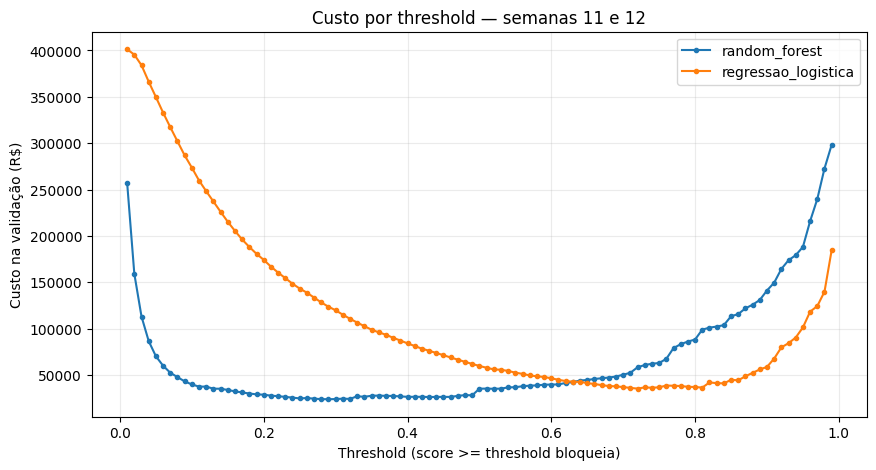

In [59]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score
from monitoramento import custo_decisao

def tabela_thresholds_modelo(resultado):
    tabela = resultado["thresholds"].copy()
    tabela["modelo"] = resultado["nome"]
    return tabela

tabela_custos = pd.concat(
    [tabela_thresholds_modelo(resultado) for resultado in modelos],
    ignore_index=True,
)

plt.figure(figsize=(10, 5))
for nome, grupo in tabela_custos.groupby("modelo"):
    plt.plot(grupo["threshold"], grupo["custo"], marker=".", label=nome)
plt.xlabel("Threshold (score >= threshold bloqueia)")
plt.ylabel("Custo na validação (R$)")
plt.title("Custo por threshold — semanas 11 e 12")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

In [60]:
linhas_avaliacao = []
for resultado in modelos:
    y = validacao["fraude"]
    valores = validacao["valor_transacao"]
    scores = resultado["scores"]
    t = resultado["threshold"]
    decisao = scores >= t
    linhas_avaliacao.append({
        "modelo": resultado["nome"],
        "cenario": "threshold_otimo",
        "threshold": t,
        "recall": recall_score(y, decisao, zero_division=0),
        "precision": precision_score(y, decisao, zero_division=0),
        "custo": custo_decisao(y, valores, scores, t),
        "legitimos_bloqueados": int(((y == 0) & decisao).sum()),
        "fraudes_aprovadas": int(((y == 1) & ~decisao).sum()),
    })

    for threshold, nome in [(0.5, "modelo_threshold_0.5")]:
        decisao = scores >= threshold
        linhas_avaliacao.append({
            "modelo": resultado["nome"],
            "cenario": nome,
            "threshold": threshold,
            "recall": recall_score(y, decisao, zero_division=0),
            "precision": precision_score(y, decisao, zero_division=0),
            "custo": custo_decisao(y, valores, scores, threshold),
            "legitimos_bloqueados": int(((y == 0) & decisao).sum()),
            "fraudes_aprovadas": int(((y == 1) & ~decisao).sum()),
        })

# Pisos do negócio, independentes do modelo.
aprovar_tudo = np.zeros(len(validacao), dtype=bool)
pix_acima_mil = (validacao["canal"] == "pix") & (validacao["valor_transacao"] > 1000)
for nome, decisao in [("aprovar_tudo", aprovar_tudo), ("regra_pix_acima_1000", pix_acima_mil)]:
    linhas_avaliacao.append({
        "modelo": "piso_negocio",
        "cenario": nome,
        "threshold": np.nan,
        "recall": recall_score(validacao["fraude"], decisao, zero_division=0),
        "precision": precision_score(validacao["fraude"], decisao, zero_division=0),
        "custo": custo_decisao(validacao["fraude"], validacao["valor_transacao"], np.where(decisao, 1.0, 0.0), 0.5),
        "legitimos_bloqueados": int(((validacao["fraude"] == 0) & decisao).sum()),
        "fraudes_aprovadas": int(((validacao["fraude"] == 1) & ~decisao).sum()),
    })

avaliacao_custos = pd.DataFrame(linhas_avaliacao)
display(avaliacao_custos.sort_values("custo").style.format({"recall": "{:.2%}", "precision": "{:.2%}", "custo": "R$ {:,.2f}"}))

melhor = avaliacao_custos[avaliacao_custos["cenario"] == "threshold_otimo"].sort_values("custo").iloc[0]
regra_atual = avaliacao_custos[avaliacao_custos["cenario"] == "regra_pix_acima_1000"].iloc[0]
print(f"Justificativa sugerida: escolho o {melhor['modelo']} com threshold {melhor['threshold']:.2f}.")
print(f"Na validação, ele custou R$ {melhor['custo']:,.2f}, bloqueou {int(melhor['legitimos_bloqueados'])} transações legítimas e deixou passar {int(melhor['fraudes_aprovadas'])} fraudes.")
print(f"A economia contra a regra atual foi de R$ {regra_atual['custo'] - melhor['custo']:,.2f}.")
print(f"O recall foi de {melhor['recall']:.2%} e a precision de {melhor['precision']:.2%}; a PR-AUC de 0.8229 apoia a qualidade do ranking, mas a escolha foi feita pelo menor custo.")

,modelo,cenario,threshold,recall,precision,custo,legitimos_bloqueados,fraudes_aprovadas
2,random_forest,threshold_otimo,0.290000,86.00%,44.18%,"R$ 24,023.14",652,84
3,random_forest,modelo_threshold_0.5,0.500000,78.00%,74.29%,"R$ 35,381.44",162,132
0,regressao_logistica,threshold_otimo,0.720000,79.17%,27.25%,"R$ 35,477.50",1268,125
1,regressao_logistica,modelo_threshold_0.5,0.500000,86.83%,13.21%,"R$ 59,885.64",3423,79
5,piso_negocio,regra_pix_acima_1000,nan,9.83%,23.69%,"R$ 225,349.79",190,541
4,piso_negocio,aprovar_tudo,nan,0.00%,0.00%,"R$ 376,035.53",0,600


Justificativa sugerida: escolho o random_forest com threshold 0.29.
Na validação, ele custou R$ 24,023.14, bloqueou 652 transações legítimas e deixou passar 84 fraudes.
A economia contra a regra atual foi de R$ 201,326.65.
O recall foi de 86.00% e a precision de 44.18%; a PR-AUC de 0.8229 apoia a qualidade do ranking, mas a escolha foi feita pelo menor custo.


In [61]:
# O threshold e o custo ótimos já foram registrados como métricas nas runs da seção 4.
print("Use a tabela acima para escolher o modelo e justificar a decisão na seção 6.")

Use a tabela acima para escolher o modelo e justificar a decisão na seção 6.


## 6. A escolha

Em uma célula de texto, escolha o modelo que vai para produção e justifique **em linguagem de custo**, como você explicaria para a Helena: quanto ele custa por semana na validação, quanto economiza em relação à regra atual, quantos clientes legítimos ele incomoda e quanta fraude ainda passa.

Não vale "porque teve a maior PR-AUC". Vale usar a PR-AUC como argumento de apoio.

*Sua justificativa:*

Escolho o Random Forest com threshold de 0,29. Foi a opção de menor custo na validação das semanas 11 e 12, com R$ 24.023,14 no total e média de R$ 12.011,57 por semana. A regra de bloquear Pix acima de R$ 1.000 custou R$ 225.349,79 no mesmo período. A economia foi de R$ 201.326,65 nas duas semanas.

O modelo bloqueou 652 transações legítimas para verificação e ainda aprovou 84 das 600 fraudes. O recall foi de 86,00%, a precisão de 44,18% e a PR-AUC de 0,8229.

## 7. Registro e promoção

**Faça**
1. Registre o modelo escolhido no Model Registry com o nome **`antifraude`** (é o nome que o sistema procura).
2. Na **versão** registrada (não na run), grave as tags:
   - `threshold` — o corte escolhido na seção 5 (o sistema lê daqui);
   - `motivo` — uma frase curta, ex.: `v1.0.0 - primeiro modelo em produção` (aparece no histórico de trocas do sistema).
3. Escreva uma **descrição** para a versão: algoritmo, threshold e por que foi escolhido.
4. Aponte o alias **`champion`** para essa versão.

Use o `MlflowClient` para os passos 2 a 4.

In [62]:
# Registro e promoção: a seleção vem da tabela de custos da seção 5.
from mlflow.exceptions import MlflowException

mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
cli = MlflowClient()

melhor = min(modelos, key=lambda resultado: resultado["custo"])
nome_algoritmo = melhor["nome"]
threshold_escolhido = float(melhor["threshold"])
run_id_escolhida = melhor["run_id"]
# MLflow 3 usa a URI do LoggedModel (models:/m-...), que aponta para o artefato correto.
source = melhor["model_uri"]

# Cria o registered model uma única vez; as execuções seguintes criam nova versão.
try:
    cli.get_registered_model(config.NOME_MODELO)
except MlflowException:
    cli.create_registered_model(
        config.NOME_MODELO,
        description="Modelo de antifraude selecionado pelo menor custo na validação.",
    )

versao = cli.create_model_version(
    name=config.NOME_MODELO,
    source=source,
    run_id=run_id_escolhida,
)
motivo = "v1.0.0 - primeiro modelo em produção"
descricao = (
    f"Algoritmo: {nome_algoritmo}. Threshold: {threshold_escolhido:.2f}. "
    f"Escolhido pelo menor custo financeiro na validação das semanas 11 e 12 "
    f"(R$ {melhor['custo']:,.2f}), equilibrando fraude aprovada e bloqueios legítimos."
)

# Tags, descrição e alias são propriedades da VERSÃO registrada.
cli.set_model_version_tag(config.NOME_MODELO, versao.version, config.TAG_THRESHOLD, str(threshold_escolhido))
cli.set_model_version_tag(config.NOME_MODELO, versao.version, config.TAG_MOTIVO, motivo)
cli.update_model_version(config.NOME_MODELO, versao.version, description=descricao)
cli.set_registered_model_alias(config.NOME_MODELO, config.ALIAS_PRODUCAO, versao.version)

print(f"Registrado: {config.NOME_MODELO} v{versao.version}")
print(f"Algoritmo: {nome_algoritmo} | threshold: {threshold_escolhido:.2f}")
print(f"Alias @{config.ALIAS_PRODUCAO} -> v{versao.version}")

2026/11/07 20:33:33 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: antifraude, version 3


Registrado: antifraude v3
Algoritmo: random_forest | threshold: 0.29
Alias @champion -> v3


## 8. O sistema está usando o seu modelo?

Abra http://127.0.0.1:8000/modelo: deve aparecer a sua versão e o seu threshold.

**Faça**
1. Pegue 5 transações da semana 12 (só as 13 features) e mande para `POST /predict` do sistema (lista de objetos JSON).
2. Pontue as mesmas 5 transações com o modelo carregado do MLflow (`models:/antifraude@champion`) no notebook.
3. Confira que os scores são **idênticos** e que a decisão (bloquear ou não) bate com o seu threshold.

> Se os scores forem diferentes, há alguma transformação acontecendo de um jeito no notebook e de outro em produção. É exatamente o tipo de bug que o contrato existe para evitar.

In [70]:
import json
import urllib.request

import mlflow
import pandas as pd
from mlflow.tracking import MlflowClient

import config
from features import carregar_contrato

mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
uri_champion = f"models:/{config.NOME_MODELO}@{config.ALIAS_PRODUCAO}"
champion = MlflowClient().get_model_version_by_alias(config.NOME_MODELO, config.ALIAS_PRODUCAO)
threshold = float(champion.tags[config.TAG_THRESHOLD])
modelo_champion = mlflow.sklearn.load_model(uri_champion)

with urllib.request.urlopen(f"{config.SISTEMA_URL}/api/modelo", timeout=15) as resposta:
    status = json.load(resposta)["modelo"]
assert status["ok"] and str(status["versao"]) == str(champion.version), status
assert status["threshold"] == threshold, status
print(f"Modelo no sistema: {config.NOME_MODELO} v{champion.version} | threshold {threshold:.2f}")

colunas = [feature["nome"] for feature in carregar_contrato()["features"]]
transacoes = pd.read_csv("dados/transacoes_semanas_01_12.csv", usecols=["semana", *colunas])
candidatas = transacoes.loc[transacoes["semana"].eq(12), colunas].head(100)
scores = modelo_champion.predict_proba(candidatas)[:, 1]
indices = candidatas.index
selecionadas = indices[scores < threshold][:3].append(indices[scores >= threshold][:2])
amostra = candidatas.loc[selecionadas]
assert len(amostra) == 5, "A amostra deve cobrir três aprovações e dois bloqueios."
scores_locais = modelo_champion.predict_proba(amostra)[:, 1]

requisicao = urllib.request.Request(
    f"{config.SISTEMA_URL}/predict",
    data=amostra.to_json(orient="records").encode("utf-8"),
    headers={"Content-Type": "application/json"},
    method="POST",
)
with urllib.request.urlopen(requisicao, timeout=15) as resposta:
    previsoes = json.load(resposta)

esperado = [
    {"score": round(float(score), 6), "bloquear": bool(score >= threshold),
     "threshold": threshold, "versao_modelo": str(champion.version)}
    for score in scores_locais
]
assert previsoes == esperado, (previsoes, esperado)
print(json.dumps(previsoes, indent=2, ensure_ascii=False))
print("OK: os cinco scores coincidem a seis casas decimais, e as decisões também coincidem.")

Modelo no sistema: antifraude v3 | threshold 0.29
[
  {
    "score": 0.011334,
    "bloquear": false,
    "threshold": 0.29,
    "versao_modelo": "3"
  },
  {
    "score": 0.19165,
    "bloquear": false,
    "threshold": 0.29,
    "versao_modelo": "3"
  },
  {
    "score": 0.043286,
    "bloquear": false,
    "threshold": 0.29,
    "versao_modelo": "3"
  },
  {
    "score": 0.303828,
    "bloquear": true,
    "threshold": 0.29,
    "versao_modelo": "3"
  },
  {
    "score": 0.976703,
    "bloquear": true,
    "threshold": 0.29,
    "versao_modelo": "3"
  }
]
OK: os cinco scores coincidem a seis casas decimais, e as decisões também coincidem.


## 9. Monitoramento baseline

A partir de quarta-feira chegam as semanas novas, uma por vez, e os rótulos de cada semana chegam só uma semana depois. O seu monitoramento precisa estar pronto **antes**, para que você perceba problemas sem esperar o negócio reclamar.

### 9.1 Referência
A referência é a "foto" de como os dados e os scores eram quando o modelo foi aprovado: as features da **validação** (semanas 11 e 12), o score do modelo escolhido e o rótulo.
- Salve a referência em arquivo e registre-a como **artefato da run do modelo campeão**, na pasta `referencia/` (`mlflow.log_artifacts(..., artifact_path="referencia", run_id=...)`). Assim, trocou o modelo, trocou a referência.

### 9.2 `monitoramento.py`
Escreva funções reutilizáveis que recebam a referência e um lote e devolvam tabelas legíveis:
- **Drift das features contínuas e do score**: teste **KS**, reportando a **estatística D** e o p-valor.
- **Drift das categóricas e booleanas** (e da hora): qui-quadrado ou comparação de proporções.
- **Saída do modelo**: taxa de bloqueio e valor bloqueado.
- **Performance, para quando o rótulo chegar**: recall, precision, PR-AUC e custo — **globais e por segmento** (uma coluna à sua escolha, ex.: `canal`).

### 9.3 Relatório zero
Rode o monitoramento comparando a **semana 11 com a semana 12** (as duas são da validação, nada mudou de propósito entre elas).
- Olhe os p-valores e as estatísticas. Algum p-valor é minúsculo mesmo sem nenhuma mudança relevante? Por quê?
- Defina e **justifique por escrito** os seus limites de alerta (ex.: D > 0,1). Eles valem para as próximas partes.

> O que você vai receber a cada semana: o CSV de transações (que você envia em **Lotes** no sistema) e, a partir da segunda semana, o CSV de rótulos da semana anterior (em **Rótulos**). Os dados já pontuados ficam em `GET /api/semanas/{n}/dados.csv`, com o score e, quando houver, o rótulo. É daí que o seu monitoramento vai ler.

In [65]:
import importlib
import monitoramento
importlib.reload(monitoramento)  # atualiza o módulo já carregado pelo notebook

from preparar_monitoramento import preparar

versao_monitoramento, tabelas_zero = preparar()
print(f'Referência registrada na run {versao_monitoramento.run_id} do champion v{versao_monitoramento.version}')


Referência registrada na run 7260ffdde12740b38a547f1a41c50a98 do champion v3


In [66]:
from IPython.display import display

display(tabelas_zero['continuas'])
display(tabelas_zero['discretas'])


,variavel,n_referencia,n_lote,media_referencia,media_lote,D,p_valor,alerta
0,valor_transacao,20399,19098,185.064186,186.377662,0.005072,9.603717e-01,False
1,qtd_transacoes_1h,20399,19098,0.366391,0.364436,0.003560,9.996003e-01,False
2,valor_medio_30d,20399,19098,117.797492,118.408119,0.005520,9.229411e-01,False
3,razao_valor_media,20399,19098,1.579521,1.583691,0.008002,5.499612e-01,False
4,distancia_ultima_transacao_km,20399,19098,21.575116,22.658797,0.008460,4.777147e-01,False
5,idade_conta_dias,20399,19098,816.603510,815.868677,0.059378,1.130019e-30,False
6,score,20399,19098,0.038196,0.037860,0.007378,6.533277e-01,False


,variavel,n_referencia,n_lote,categorias,categoria_maior_mudanca,maior_mudanca_pp,p_valor,alerta
0,hora_transacao,20399,19098,24,13,0.508399,0.208864,False
1,dia_semana,20399,19098,7,2,0.805266,0.373101,False
2,canal,20399,19098,3,cartao_presencial,0.458228,0.562775,False
3,dispositivo_novo,20399,19098,2,0,0.210803,0.281195,False
4,destinatario_novo,20399,19098,2,0,0.635776,0.135334,False
5,categoria_estabelecimento,20399,19098,10,transferencia_pessoal,0.567154,0.159546,False
6,uf_cliente,20399,19098,27,PR,0.694764,0.303849,False


In [67]:
display(tabelas_zero['saida'])
display(tabelas_zero['performance'])


,conjunto,transacoes,bloqueios,taxa_bloqueio,valor_bloqueado,valor_total,pct_valor_bloqueado,delta_taxa_bloqueio_pp,delta_pct_valor_bloqueado_pp,alerta
0,referencia,20399,612,0.030001,282599.52,3775124.34,0.074858,0.000000,0.000000,False
1,lote,19098,556,0.029113,275084.52,3559440.59,0.077283,-0.088847,0.242474,False


,conjunto,segmento,valor_segmento,transacoes,fraudes,recall,precision,pr_auc,custo,custo_por_mil,motivos_alerta,alerta
0,referencia,global,todos,20399,309,0.864078,0.436275,0.821672,10551.35,517.248395,,False
1,referencia,canal,cartao_online,5098,96,0.906250,0.426471,0.868276,3489.35,684.454688,,False
2,referencia,canal,cartao_presencial,6154,66,0.757576,0.387597,0.651596,2831.93,460.177121,,False
3,referencia,canal,pix,9147,147,0.884354,0.465950,0.853462,4230.07,462.454357,,False
4,lote,global,todos,19098,291,0.855670,0.447842,0.824252,13471.79,705.403184,,False
5,lote,canal,cartao_online,4773,105,0.895238,0.494737,0.860107,5239.35,1097.705845,,False
6,lote,canal,cartao_presencial,5674,47,0.723404,0.317757,0.595669,4658.86,821.089179,,False
7,lote,canal,pix,8651,139,0.870504,0.467181,0.861085,3573.58,413.082881,,False


In [68]:
from monitoramento import carregar_referencia_champion, carregar_semana, monitorar

referencia_atual, threshold_atual, versao_atual = carregar_referencia_champion()
print(f'Champion v{versao_atual}: {len(referencia_atual)} linhas na referência; threshold {threshold_atual}')
# Depois de enviar um lote em Lotes, use:
# lote = carregar_semana(13)
# tabelas = monitorar(referencia_atual, lote, threshold_atual)
# Quando os rótulos chegarem em Rótulos, rode as três linhas novamente.


Champion v3: 39497 linhas na referência; threshold 0.29


*Limites de alerta e justificativa:*

Para identificar possíveis mudanças nos dados, definimos alguns limites. No teste KS, consideramos valores de D acima de 0,10 para as variáveis contínuas e o score. Já nas variáveis categóricas, booleanas, hora e dia, consideramos mudanças maiores que 5 pontos percentuais. No controle zero, o maior valor de D foi 0,0594 na variável `idade_conta_dias`, enquanto nas outras variáveis a maior diferença foi de apenas 0,81 pp.

Também definimos limites para a saída do modelo, considerando mudanças maiores que 1 pp na taxa de bloqueio ou 3 pp na parcela do valor bloqueado. Quando temos os rótulos completos, analisamos quedas maiores que 5 pp em recall, precision ou PR-AUC, além de aumentos acima de 50% no custo por 1.000 transações. Por `canal`, consideramos quedas maiores que 10 pp, desde que existam pelo menos 100 fraudes.

Um ponto interessante foi que a variável `idade_conta_dias` apresentou um p-valor de aproximadamente 1,13 × 10⁻³⁰, mesmo com D = 0,0594. Isso acontece porque temos quase 20 mil transações por semana, então o teste KS consegue identificar até pequenas mudanças nos dados. Além disso, é normal que as contas fiquem mais antigas com o tempo. Por isso, não faz sentido gerar um alerta apenas pelo p-valor, sendo necessário analisar também o tamanho da mudança. As tabelas e comparações estão no arquivo `relatorio_zero/README.md`.


## 10. Entrega

1. Escreva a entrada **v1.0.0** no `CHANGELOG.md`, seguindo o modelo do próprio arquivo.
2. Confira a checklist:
   - [x] `antifraude@champion` aponta para o modelo escolhido, com tags `threshold` e `motivo` e descrição;
   - [x] a run do champion tem a referência em `referencia/`;
   - [x] o sistema mostra a sua versão em **Modelo**, e o teste da seção 8 bateu;
   - [x] `features.py` e `monitoramento.py` têm o seu código;
   - [x] as células de texto (seções 2, 6 e 9) estão respondidas.
3. Preencha o seu nome, **salve o notebook** e rode a célula abaixo. Ela gera a pasta `entrega/` (evidências do MLflow, modelo exportado, referência, seus arquivos) e o `entrega_parte1_<nome>.zip`.
4. Entregue o `.zip` na atividade. Se a célula listar **avisos**, resolva antes de entregar.

> A célula não mexe em nada no MLflow nem no sistema: ela só lê e copia.

In [71]:
# CÉLULA PRONTA — gera a pasta entrega/ e o entrega_parte1_<nome>.zip.
# 1) Preencha o seu nome.  2) SALVE o notebook (Ctrl+S).  3) Rode.
NOME_ALUNO = "Levy Guilherme Lemos Rios"

import datetime
import json
import shutil
import urllib.request
from pathlib import Path

import mlflow
from mlflow.tracking import MlflowClient

import config

assert NOME_ALUNO.strip(), "Preencha NOME_ALUNO antes de rodar."
mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
cli = MlflowClient()
mv = cli.get_model_version_by_alias(config.NOME_MODELO, config.ALIAS_PRODUCAO)
run = cli.get_run(mv.run_id)
art_raiz = [a.path for a in cli.list_artifacts(mv.run_id)]
art_ref = [a.path for a in cli.list_artifacts(mv.run_id, "referencia")]
saude = json.loads(urllib.request.urlopen(f"{config.SISTEMA_URL}/saude", timeout=5).read())

avisos = []
if config.TAG_THRESHOLD not in mv.tags:
    avisos.append("a versão champion não tem a tag 'threshold'")
if not mv.description:
    avisos.append("a versão champion não tem descrição")
if config.TAG_MOTIVO not in mv.tags:
    avisos.append("a versão champion não tem a tag 'motivo'")
if not art_ref:
    avisos.append("a run do champion não tem artefatos em 'referencia/'")
if str(saude["modelo"].get("versao")) != str(mv.version):
    avisos.append("o sistema não está usando a mesma versão que o MLflow aponta como champion")
for arq in ["features.py", "monitoramento.py"]:
    linhas = [l for l in Path(arq).read_text(encoding="utf-8").splitlines() if l.strip() and not l.lstrip().startswith("#")]
    if sum(1 for l in linhas if l.lstrip().startswith(("def ", "class ", "import ", "from "))) == 0:
        avisos.append(f"{arq} parece vazio")
if "## v1.0.0" not in Path("CHANGELOG.md").read_text(encoding="utf-8"):
    avisos.append("CHANGELOG.md não tem a entrada v1.0.0")

evidencias = {
    "aluno": NOME_ALUNO.strip(),
    "gerado_em": datetime.datetime.now().isoformat(timespec="seconds"),
    "modelo": config.NOME_MODELO, "alias": config.ALIAS_PRODUCAO,
    "versao": mv.version, "descricao": mv.description, "tags_versao": dict(mv.tags),
    "run_id": mv.run_id, "experimento": run.info.experiment_id,
    "params": run.data.params, "metricas": run.data.metrics,
    "artefatos": art_raiz, "referencia": art_ref,
    "sistema": saude, "avisos": avisos,
}

pasta = Path("entrega")
shutil.rmtree(pasta, ignore_errors=True)
pasta.mkdir()
(pasta / "evidencias_mlflow.json").write_text(json.dumps(evidencias, indent=2, ensure_ascii=False), encoding="utf-8")
mlflow.artifacts.download_artifacts(artifact_uri=f"models:/{config.NOME_MODELO}@{config.ALIAS_PRODUCAO}",
                                    dst_path=str(pasta / "modelo_exportado"))
mlflow.artifacts.download_artifacts(run_id=mv.run_id, artifact_path="referencia", dst_path=str(pasta)) if art_ref else None
for arq in ["parte1.ipynb", "features.py", "monitoramento.py", "CHANGELOG.md", "contrato/contrato_features.yaml"]:
    shutil.copy(arq, pasta / Path(arq).name)

nome_zip = "entrega_parte1_" + "_".join(NOME_ALUNO.lower().split())
shutil.make_archive(nome_zip, "zip", pasta)
print(f"champion: {config.NOME_MODELO} v{mv.version} | threshold {mv.tags.get(config.TAG_THRESHOLD)}")
print("AVISOS:" if avisos else "Nenhum aviso.", *avisos, sep="\n  - ")
print(f"\nEntregue o arquivo {nome_zip}.zip")

champion: antifraude v3 | threshold 0.29
Nenhum aviso.

Entregue o arquivo entrega_parte1_levy_guilherme_lemos_rios.zip
